# 👖 Autoencoders on Fashion MNIST

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, datasets, callbacks
import tensorflow.keras.backend as K

2026-11-02 23:20:54.471560: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-02 23:20:54.509207: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-02 23:20:55.954111: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
IMAGE_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 3

In [3]:
def sample_batch(dataset):
    
    batch = dataset.take(1).get_single_element()
    
    if isinstance(batch, tuple):
        batch = batch[0]
    
    return batch.numpy()


def display(images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None):
    
    
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()

## 1. Prepare the data <a name="prepare"></a>

In [4]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

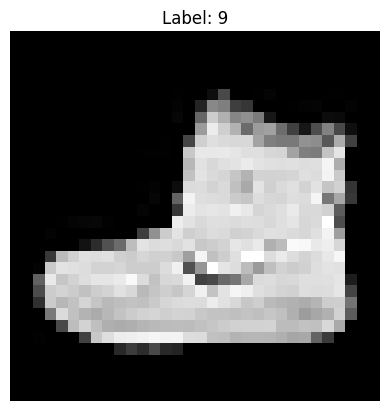

(32, 32, 1)


In [13]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()
print(x_train[0].shape)

In [5]:
# Preprocess the data
def preprocess(imgs):

    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)

    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

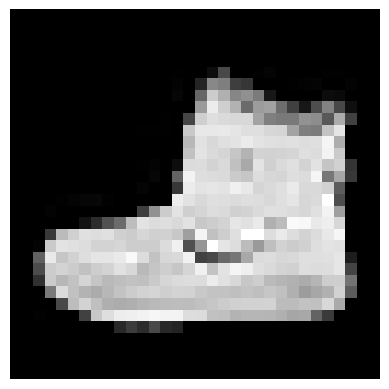

(32, 32, 1)


In [12]:
plt.imshow(x_train[0], cmap="gray")
plt.axis("off")
plt.show()
print(x_train[0].shape)

## 2. Build the autoencoder <a name="build"></a>

In [14]:
# Encoder
encoder_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input")
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(encoder_input)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = x.shape[1:]

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output)

I0000 00:00:1793642910.474184     900 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:01:00.0, compute capability: 8.9


In [22]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
decoder_output = layers.Conv2D(CHANNELS, (3, 3), strides=1, activation="sigmoid", padding="same", name="decoder_output")(x)

decoder = models.Model(decoder_input, decoder_output)

In [23]:
# Autoencoder
autoencoder = models.Model(encoder_input, decoder(encoder_output))

## 3. Train the autoencoder <a name="train"></a>

In [24]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

In [31]:
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="autoencoder.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

In [32]:
autoencoder.fit(
    x_train,
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    callbacks=[model_checkpoint_callback, tensorboard_callback]
)

Epoch 1/3
599/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2527
Epoch 1: loss improved from None to 0.25253, saving model to autoencoder.keras

Epoch 1: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.2525 - val_loss: 0.2535
Epoch 2/3
596/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2509
Epoch 2: loss improved from 0.25253 to 0.25100, saving model to autoencoder.keras

Epoch 2: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.2510 - val_loss: 0.2515
Epoch 3/3
591/600 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2500
Epoch 3: loss improved from 0.25100 to 0.24982, saving model to autoencoder.keras

Epoch 3: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.2498 - val_loss: 0.2514


In [33]:
autoencoder.save("autoencoder.keras")
encoder.save("encoder.keras")
decoder.save("decoder.keras")

## 4. Reconstruct using the autoencoder <a name="reconstruct"></a>

In [77]:
n = 10000
example_images = x_test[:n]
example_labels = y_test[:n]

In [78]:
predictions = autoencoder.predict(example_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


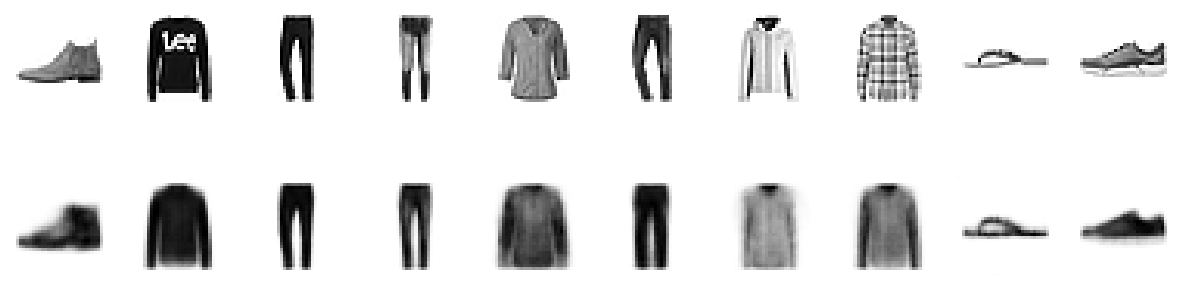

In [79]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(example_images[i], cmap="gray_r")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(predictions[i], cmap="gray_r")
    plt.axis("off")

plt.show()

## 5. Embed using the encoder <a name="encode"></a>

In [80]:
embeddings = encoder.predict(example_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [81]:
print(embeddings[:10])

[[ 1.9627473  -0.3892646 ]
 [-1.3978689  -4.7358274 ]
 [-7.4004116   1.2236015 ]
 [-4.3662333   1.2823507 ]
 [-0.35249627 -2.5237806 ]
 [-5.378674   -0.02902492]
 [-0.9498968  -1.234309  ]
 [-0.70581496 -2.0438168 ]
 [ 3.026433    2.3040757 ]
 [ 3.9876552   0.60932434]]


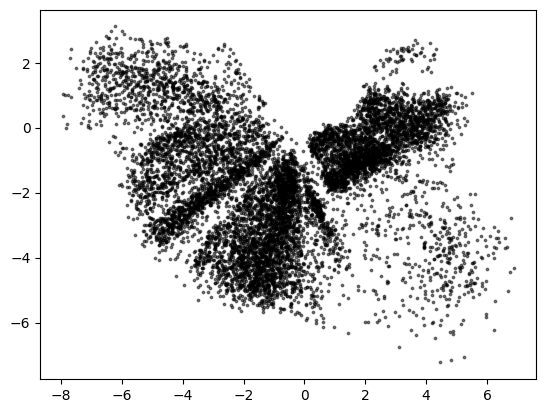

In [84]:
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=3)
plt.show()

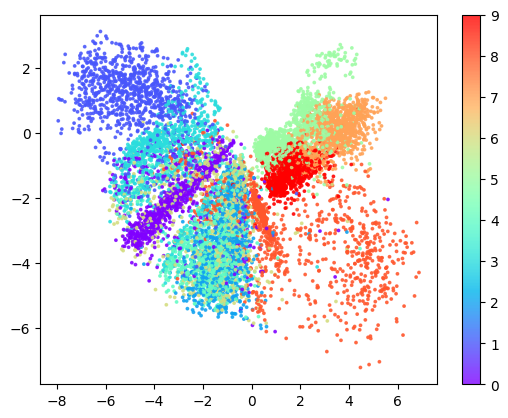

In [86]:
plt.scatter(embeddings[:, 0], embeddings[:, 1], c=y_test[:n], cmap="rainbow", alpha=0.8, s=3)
plt.colorbar()
plt.show()

## 6. Generate using the decoder <a name="decode"></a>

In [87]:
# Get the range of the existing embeddings
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)

# Sample some points in the latent space
grid_width, grid_height = (6, 3)
sample = np.random.uniform(mins, maxs, size=(grid_width * grid_height, EMBEDDING_DIM))

In [88]:
# Decode the sampled points
reconstructions = decoder.predict(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step


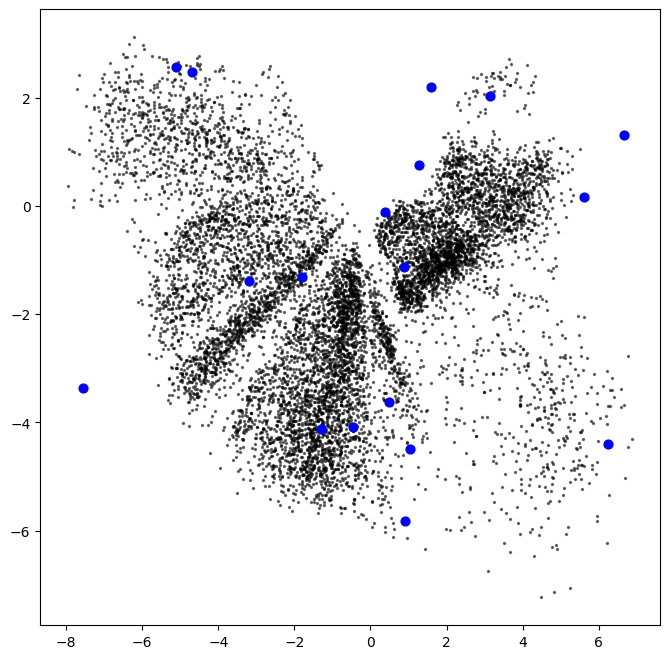

In [95]:
# Plot original and generated latent points
plt.figure(figsize=(8, 8))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=2)
plt.scatter(sample[:, 0], sample[:, 1], c="blue", s=40)
plt.show()

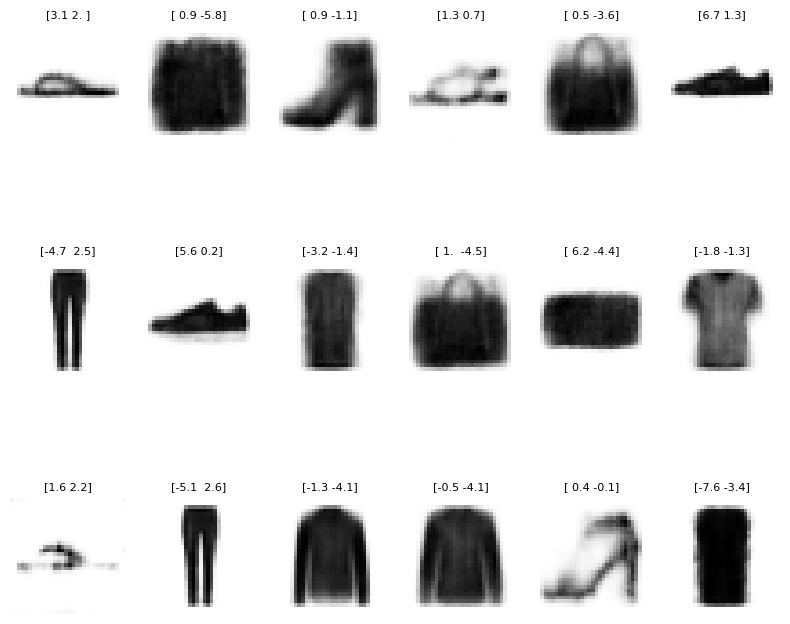

In [96]:
# Display generated images
plt.figure(figsize=(8, 8))

for i in range(grid_width * grid_height):
    plt.subplot(grid_height, grid_width, i + 1)
    plt.imshow(reconstructions[i], cmap="gray_r")
    plt.title(str(np.round(sample[i], 1)), fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

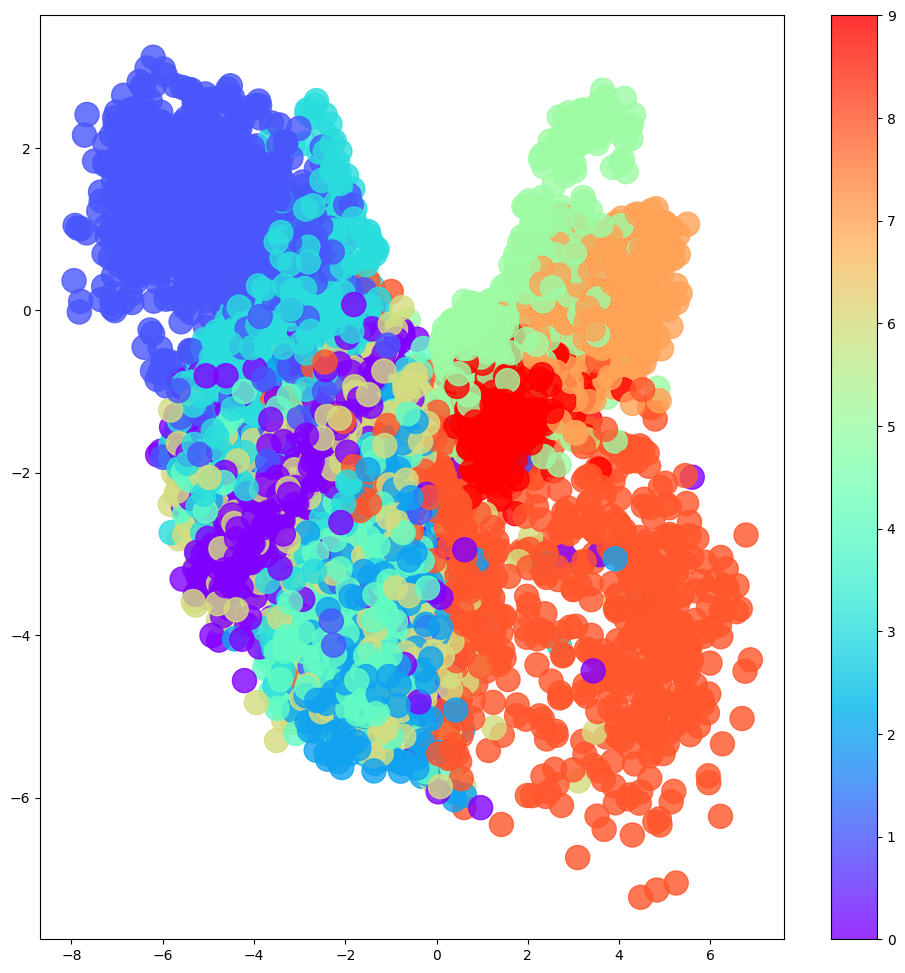

In [100]:
# Plot embeddings by clothing type
plt.figure(figsize=(12, 12))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c=example_labels, cmap="rainbow", alpha=0.8, s=300)
plt.colorbar()
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


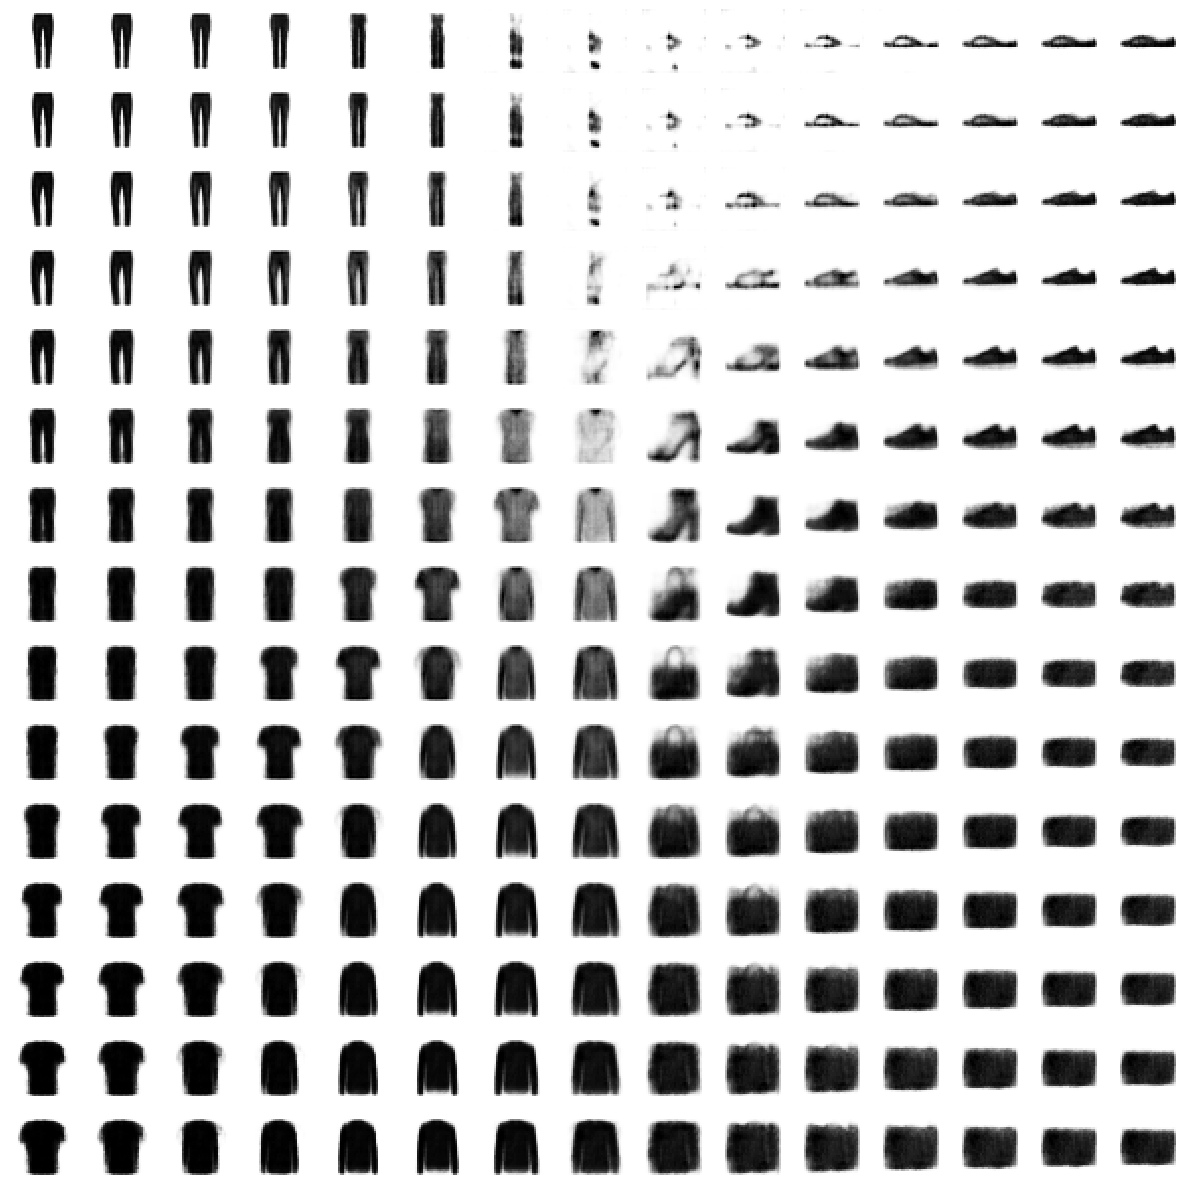

In [101]:
# Generate a grid of latent points
grid_size = 15
x = np.linspace(embeddings[:, 0].min(), embeddings[:, 0].max(), grid_size)
y = np.linspace(embeddings[:, 1].max(), embeddings[:, 1].min(), grid_size)
x, y = np.meshgrid(x, y)
grid = np.column_stack((x.flatten(), y.flatten()))


# Generate images from latent points
reconstructions = decoder.predict(grid)


# Display generated images
plt.figure(figsize=(12, 12))

for i in range(grid_size ** 2):
    plt.subplot(grid_size, grid_size, i + 1)
    plt.imshow(reconstructions[i].squeeze(), cmap="gray_r")
    plt.axis("off")

plt.tight_layout()
plt.show()